In [40]:
# ==================== IMPORT THƯ VIỆN ====================
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
# TODO: Import thư viện underthesea để tách từ tiếng Việt
from underthesea import word_tokenize

In [41]:
# ==================== PHẦN 1: CHUẨN BỊ DỮ LIỆU ====================
print("=" * 60)
print("PHẦN 1: CHUẨN BỊ DỮ LIỆU")
print("=" * 60)

# Dataset mẫu: Các câu đánh giá về sản phẩm/dịch vụ
documents = [
    "Sản phẩm này rất tốt, tôi rất hài lòng với chất lượng",
    "Dịch vụ giao hàng nhanh, nhân viên nhiệt tình",
    "Chất lượng sản phẩm tệ, không đáng tiền",
    "Tôi không hài lòng với sản phẩm này, giao hàng chậm",
    "Rất tốt, sẽ quay lại mua hàng lần sau",
    "Nhân viên tư vấn nhiệt tình, sản phẩm chất lượng cao",
    "Giao hàng chậm trễ, sản phẩm không như mô tả",
    "Tuyệt vời! Sản phẩm vượt ngoài mong đợi của tôi"
]

print(f"Tổng số văn bản: {len(documents)}")
print("\nVí dụ văn bản gốc:")
for i, doc in enumerate(documents[:3]):
    print(f"{i+1}. {doc}")


PHẦN 1: CHUẨN BỊ DỮ LIỆU
Tổng số văn bản: 8

Ví dụ văn bản gốc:
1. Sản phẩm này rất tốt, tôi rất hài lòng với chất lượng
2. Dịch vụ giao hàng nhanh, nhân viên nhiệt tình
3. Chất lượng sản phẩm tệ, không đáng tiền


In [42]:
# ==================== PHẦN 2: TÁCH TỪ TIẾNG VIỆT ====================
print("\n" + "=" * 60)
print("PHẦN 2: TÁCH TỪ TIẾNG VIỆT (WORD SEGMENTATION)")
print("=" * 60)

def vietnamese_word_segmentation(text):
    """
    Hàm tách từ tiếng Việt sử dụng thư viện underthesea
    
    Args:
        text (str): Văn bản đầu vào
    
    Returns:
        str: Văn bản đã được tách từ
    
    TODO: Sinh viên hoàn thiện hàm này
    Gợi ý: Sử dụng word_tokenize từ underthesea
    """
    return word_tokenize(text, format="text")

# Test hàm tách từ
sample_text = documents[0]
print(f"\nVăn bản gốc: {sample_text}")

# TODO: Gọi hàm tách từ và in kết quả
segmented_text = vietnamese_word_segmentation(sample_text)
print(f"Sau tách từ: {segmented_text}")

# Tách từ cho toàn bộ dataset
# TODO: Áp dụng hàm tách từ cho tất cả văn bản trong documents
segmented_documents = [vietnamese_word_segmentation(doc) for doc in documents]




PHẦN 2: TÁCH TỪ TIẾNG VIỆT (WORD SEGMENTATION)

Văn bản gốc: Sản phẩm này rất tốt, tôi rất hài lòng với chất lượng
Sau tách từ: Sản_phẩm này rất tốt , tôi rất hài_lòng với chất_lượng


In [43]:
# ==================== PHẦN 3: LOẠI BỎ TỪ DỪNG ====================
print("\n" + "=" * 60)
print("PHẦN 3: LOẠI BỎ TỪ DỪNG (STOPWORD REMOVAL)")
print("=" * 60)

# Danh sách từ dừng tiếng Việt (mẫu)
vietnamese_stopwords = [
    'bị', 'bởi', 'cả', 'các', 'cái', 'cần', 'càng', 'chỉ', 'chiếc',
    'cho', 'chứ', 'chưa', 'chuyện', 'có', 'có_thể', 'cứ', 'của', 'cùng',
    'cũng', 'đã', 'đang', 'đây', 'để', 'đến_nỗi', 'đều', 'điều', 'do',
    'đó', 'được', 'dưới', 'gì', 'khi', 'không', 'là', 'lại', 'lên',
    'lúc', 'mà', 'mỗi', 'một_cách', 'này', 'nên', 'nếu', 'ngay', 'nhiều',
    'như', 'nhưng', 'những', 'nơi', 'nữa', 'phải', 'qua', 'ra', 'rằng',
    'rất', 'rồi', 'sau', 'sẽ', 'so', 'sự', 'tại', 'theo', 'thì',
    'trên', 'trước', 'từ', 'từng', 'và', 'vẫn', 'vào', 'vậy', 'vì',
    'việc', 'với', 'vừa', 'tôi'
]

def remove_stopwords(text, stopwords):
    """
    Loại bỏ từ dừng khỏi văn bản
    
    Args:
        text (str): Văn bản đã tách từ (các từ cách nhau bởi dấu cách)
        stopwords (list): Danh sách từ dừng
    
    Returns:
        str: Văn bản sau khi loại bỏ từ dừng
    """
    # Tách văn bản thành list các từ
    words = text.split()
    filtered_words = [word for word in words if word.lower() not in stopwords and word not in [',', '.', '!', '?', '...', ';', ':']]
    return ' '.join(filtered_words)

# Test hàm loại bỏ từ dừng
sample_segmented = "sản_phẩm này rất tốt , tôi rất hài_lòng với chất_lượng"
print(f"\nVăn bản đã tách từ: {sample_segmented}")

# TODO: Gọi hàm loại bỏ từ dừng
cleaned_text = remove_stopwords(sample_segmented, vietnamese_stopwords)
print(f"Sau khi loại từ dừng: {cleaned_text}")

# Áp dụng cho toàn bộ dataset
# TODO: Loại bỏ từ dừng cho tất cả văn bản
cleaned_documents = [remove_stopwords(doc, vietnamese_stopwords) for doc in segmented_documents]




PHẦN 3: LOẠI BỎ TỪ DỪNG (STOPWORD REMOVAL)

Văn bản đã tách từ: sản_phẩm này rất tốt , tôi rất hài_lòng với chất_lượng
Sau khi loại từ dừng: sản_phẩm tốt hài_lòng chất_lượng


In [44]:
# ==================== PHẦN 4: BAG OF WORDS (BoW) ====================
print("\n" + "=" * 60)
print("PHẦN 4: BAG OF WORDS (BoW)")
print("=" * 60)

def create_bow_manual(documents):
    """
    Tạo Bag of Words thủ công
    
    Args:
        documents (list): Danh sách các văn bản
    
    Returns:
        tuple: (vocabulary, bow_matrix)
        - vocabulary: từ điển (dict) mapping từ -> index
        - bow_matrix: ma trận BoW (list of lists)
    
    TODO: Sinh viên hoàn thiện hàm này
    Các bước:
    1. Tạo vocabulary (từ điển) từ tất cả các từ unique
    2. Với mỗi document, đếm số lần xuất hiện của mỗi từ
    3. Tạo vector biểu diễn cho mỗi document
    """
    # Bước 1: Tạo vocabulary
    all_words = set()
    for doc in documents:
        words = doc.split()
        all_words.update(words)
    
    vocabulary = {word: idx for idx, word in enumerate(sorted(all_words))}
    
    # Bước 2 và 3: Đếm và tạo vector
    bow_matrix = []
    for doc in documents:
        vector = [0] * len(vocabulary)
        words = doc.split()
        for word in words:
            if word in vocabulary:
                vector[vocabulary[word]] += 1
        bow_matrix.append(vector)
    
    return vocabulary, bow_matrix

# TODO: Test hàm BoW thủ công
vocab, bow_matrix = create_bow_manual(cleaned_documents)
print(f"\nKích thước từ vựng: {len(vocab)}")
print(f"Kích thước ma trận BoW: {len(bow_matrix)} x {len(vocab)}")

print("\n--- Sử dụng sklearn CountVectorizer ---")
# TODO: Sử dụng CountVectorizer từ sklearn
vectorizer = CountVectorizer()
bow_matrix_sklearn = vectorizer.fit_transform(cleaned_documents)
feature_names = vectorizer.get_feature_names_out()

# TODO: In ra một số thông tin về BoW
print(f"Số lượng từ vựng: {len(feature_names)}")
print(f"Kích thước ma trận: {bow_matrix_sklearn.shape}")
print(f"\nMột số từ trong từ điển: {feature_names[:10]}")



PHẦN 4: BAG OF WORDS (BoW)

Kích thước từ vựng: 29
Kích thước ma trận BoW: 8 x 29

--- Sử dụng sklearn CountVectorizer ---
Số lượng từ vựng: 25
Kích thước ma trận: (8, 25)

Một số từ trong từ điển: ['cao' 'chất_lượng' 'chậm' 'chậm_trễ' 'dịch_vụ' 'giao' 'hài_lòng' 'hàng'
 'lần' 'mong_đợi']


In [45]:
import math

In [46]:
# ==================== PHẦN 5: TF-IDF ====================
print("\n" + "=" * 60)
print("PHẦN 5: TF-IDF (Term Frequency - Inverse Document Frequency)")
print("=" * 60)

def calculate_tf(document):
    """
    Tính Term Frequency cho một văn bản
    
    Args:
        document (str): Văn bản đầu vào
    
    Returns:
        dict: TF scores {term: tf_score}
    
    TODO: Sinh viên hoàn thiện
    Công thức: TF(t, d) = (Số lần từ t xuất hiện trong d) / (Tổng số từ trong d)
    """
    words = document.split()
    total_words = len(words)
    
    word_count = {}
    for word in words:
        if word in word_count:
            word_count[word] += 1
        else:
            word_count[word] = 1
    
    tf_scores = {}
    for word, count in word_count.items():
        tf_scores[word] = count / total_words
    
    return tf_scores

def calculate_idf(documents):
    """
    Tính Inverse Document Frequency cho tập văn bản
    
    Args:
        documents (list): Danh sách các văn bản
    
    Returns:
        dict: IDF scores {term: idf_score}
    
    TODO: Sinh viên hoàn thiện
    Công thức: IDF(t, D) = log(Tổng số văn bản / Số văn bản chứa từ t)
    """
    
    # Thu thập tất cả từ
    all_words = set()
    for doc in documents:
        words = doc.split()
        all_words.update(words)
    
    # Đếm số văn bản chứa mỗi từ
    num_docs = len(documents)
    idf_scores = {}
    
    for word in all_words:
        doc_count = 0
        for doc in documents:
            if word in doc.split():
                doc_count += 1
        idf_scores[word] = math.log(num_docs / doc_count)
    
    return idf_scores

def calculate_tfidf_manual(documents):
    """
    Tính TF-IDF cho tập văn bản
    
    Args:
        documents (list): Danh sách các văn bản
    
    Returns:
        list: Danh sách TF-IDF vectors cho mỗi văn bản
    
    TODO: Sinh viên hoàn thiện
    Công thức: TF-IDF(t, d, D) = TF(t, d) * IDF(t, D)
    """
    # Tính IDF
    idf_scores = calculate_idf(documents)
    
    # Tạo vocabulary
    all_words = set()
    for doc in documents:
        all_words.update(doc.split())
    vocabulary = {word: idx for idx, word in enumerate(sorted(all_words))}
    
    # Tính TF-IDF cho mỗi văn bản
    tfidf_matrix = []
    for doc in documents:
        tf_scores = calculate_tf(doc)
        vector = [0] * len(vocabulary)
        
        for word, tf in tf_scores.items():
            if word in vocabulary:
                tfidf = tf * idf_scores[word]
                vector[vocabulary[word]] = tfidf
        
        tfidf_matrix.append(vector)
    
    return tfidf_matrix

print("\n--- Sử dụng sklearn TfidfVectorizer ---")
# TODO: Sử dụng TfidfVectorizer từ sklearn
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cleaned_documents)
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()

# TODO: In thông tin về TF-IDF matrix
print(f"Kích thước ma trận TF-IDF: {tfidf_matrix.shape}")


PHẦN 5: TF-IDF (Term Frequency - Inverse Document Frequency)

--- Sử dụng sklearn TfidfVectorizer ---
Kích thước ma trận TF-IDF: (8, 25)


In [47]:
from scipy.sparse import issparse

In [48]:
# ==================== PHẦN 6: PHÂN TÍCH KẾT QUẢ ====================
print("\n" + "=" * 60)
print("PHẦN 6: PHÂN TÍCH VÀ SO SÁNH KẾT QUẢ")
print("=" * 60)

def display_top_terms_bow(bow_matrix, feature_names, doc_index, top_n=5):
    """
    Hiển thị top N từ quan trọng nhất trong văn bản (theo BoW)
    
    TODO: Sinh viên hoàn thiện
    """
    if issparse(bow_matrix):
        doc_vector = bow_matrix[doc_index].toarray()[0]
    else:
        doc_vector = bow_matrix[doc_index]

    word_scores = []
    
    for word, score in zip(feature_names, doc_vector):
        if score > 0:
            word_scores.append((word, score))
    
    word_scores.sort(key=lambda x: x[1], reverse=True)
    
    print(f"--- Document {doc_index + 1} ---")
    for word, score in word_scores[:top_n]:
        print(f"{word}: {score}")

def display_top_terms_tfidf(tfidf_matrix, feature_names, doc_index, top_n=5):
    """
    Hiển thị top N từ quan trọng nhất trong văn bản (theo TF-IDF)
    
    TODO: Sinh viên hoàn thiện
    """
    if issparse(tfidf_matrix):
        doc_vector = tfidf_matrix[doc_index].toarray()[0]
    else:
        doc_vector = tfidf_matrix[doc_index]

    word_scores = []
    for word, score in zip(feature_names, doc_vector):
        if score > 0:
            word_scores.append((word, score))
            
    word_scores.sort(key=lambda x: x[1], reverse=True)
    
    print(f"--- Document {doc_index + 1} ---")
    for word, score in word_scores[:top_n]:
        print(f"{word}: {score:.4f}")

# TODO: So sánh BoW và TF-IDF cho văn bản đầu tiên
print("\nVăn bản 1:", documents[0])
print("\nTop 5 từ theo BoW:")
display_top_terms_bow(bow_matrix_sklearn, feature_names, 0, 5)
print("\nTop 5 từ theo TF-IDF:")
display_top_terms_tfidf(tfidf_matrix, tfidf_feature_names, 0, 5)



PHẦN 6: PHÂN TÍCH VÀ SO SÁNH KẾT QUẢ

Văn bản 1: Sản phẩm này rất tốt, tôi rất hài lòng với chất lượng

Top 5 từ theo BoW:
--- Document 1 ---
chất_lượng: 1
hài_lòng: 1
sản_phẩm: 1
tốt: 1

Top 5 từ theo TF-IDF:
--- Document 1 ---
hài_lòng: 0.5679
tốt: 0.5679
chất_lượng: 0.4901
sản_phẩm: 0.3386


In [49]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns


PHẦN 7: TRỰC QUAN HÓA (OPTIONAL)

--- 7.1: Word Cloud ---
Tạo Word Cloud từ tất cả văn bản...
✓ Đã lưu Word Cloud vào file: wordcloud.png


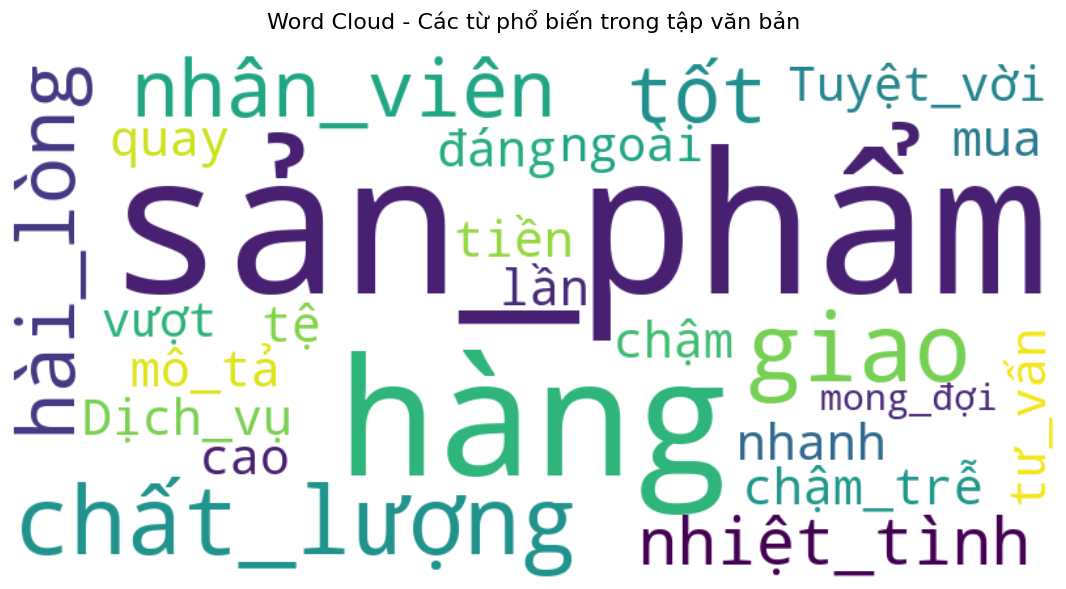


--- 7.2: Biểu đồ tần suất từ ---
Vẽ biểu đồ top 15 từ xuất hiện nhiều nhất...
✓ Đã lưu biểu đồ tần suất vào file: word_frequency.png


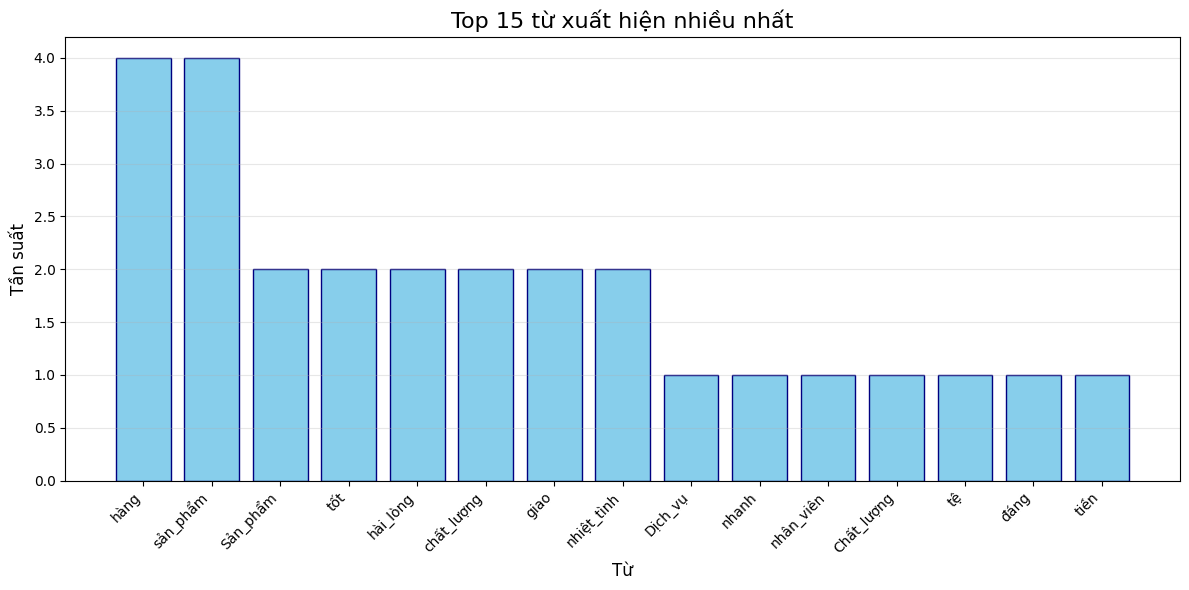


--- 7.3: Heatmap ma trận TF-IDF ---
Tạo heatmap để xem TF-IDF score của các từ trong từng văn bản...
✓ Đã lưu heatmap vào file: tfidf_heatmap.png


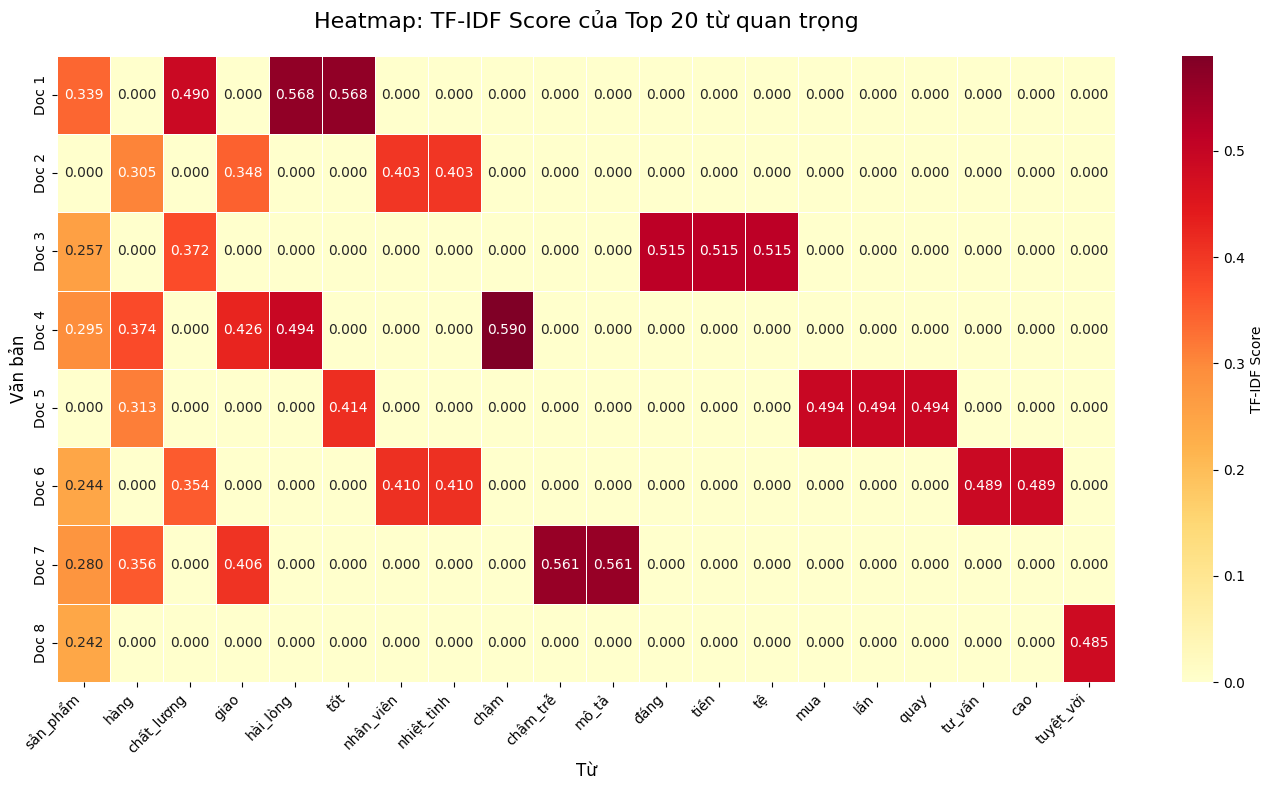


--- 7.4: So sánh BoW và TF-IDF cho 1 văn bản ---
Vẽ biểu đồ so sánh điểm số BoW và TF-IDF của văn bản đầu tiên...
✓ Đã lưu biểu đồ so sánh vào file: bow_vs_tfidf.png


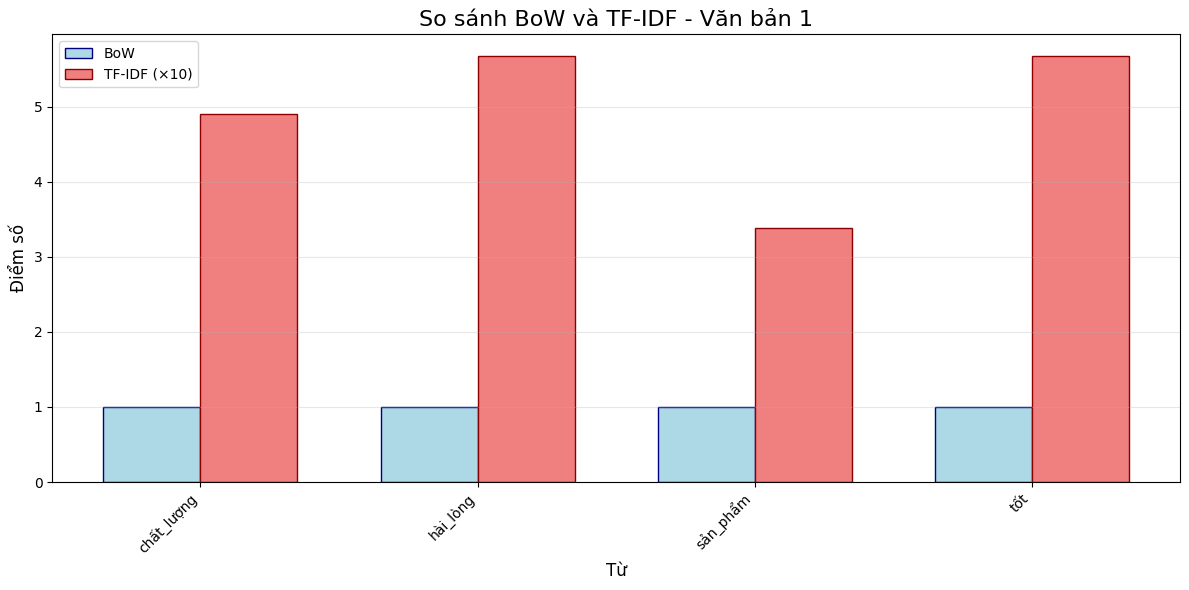


TỔNG KẾT PHÂN TÍCH

Đã tạo 8 văn bản:
- Tổng số từ unique: 29
- Từ xuất hiện nhiều nhất: hàng (4 lần)
- Từ xuất hiện ít nhất: Nhiều từ chỉ xuất hiện 1 lần

Các file đã tạo:
1. wordcloud.png - Word Cloud tổng quan
2. word_frequency.png - Biểu đồ tần suất top 15 từ
3. tfidf_heatmap.png - Heatmap TF-IDF của top 20 từ
4. bow_vs_tfidf.png - So sánh BoW và TF-IDF

Nhận xét:
- BoW phù hợp khi muốn đếm tần suất đơn giản
- TF-IDF tốt hơn khi muốn tìm từ đặc trưng của từng văn bản
- Các từ như 'sản_phẩm' xuất hiện nhiều → BoW cao, TF-IDF thấp
- Các từ đặc biệt như 'tuyệt_vời' → TF-IDF cao hơn

HOÀN THÀNH PHÂN TÍCH!


In [50]:
print("\n" + "=" * 60)
print("PHẦN 7: TRỰC QUAN HÓA (OPTIONAL)")
print("=" * 60)

# TODO (Optional): Sinh viên có thể thêm các hình ảnh trực quan hóa
# - Word Cloud
# - Heatmap của ma trận TF-IDF
# - Biểu đồ tần suất từ

plt.rcParams['font.family'] = 'DejaVu Sans'

# ==================== 7.1: WORD CLOUD ====================
print("\n--- 7.1: Word Cloud ---")
print("Tạo Word Cloud từ tất cả văn bản...")

# Ghép tất cả văn bản đã làm sạch thành 1 chuỗi
all_text = ' '.join(cleaned_documents)

# Tạo WordCloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis',
    max_words=50
).generate(all_text)

# Vẽ Word Cloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Các từ phổ biến trong tập văn bản', fontsize=16, pad=20)
plt.tight_layout()
plt.savefig('wordcloud.png', dpi=300, bbox_inches='tight')
print("✓ Đã lưu Word Cloud vào file: wordcloud.png")
plt.show()


# ==================== 7.2: BIỂU ĐỒ TẦN SUẤT TỪ ====================
print("\n--- 7.2: Biểu đồ tần suất từ ---")
print("Vẽ biểu đồ top 15 từ xuất hiện nhiều nhất...")

# Đếm tần suất tất cả các từ
word_freq = {}
for doc in cleaned_documents:
    words = doc.split()
    for word in words:
        if word in word_freq:
            word_freq[word] += 1
        else:
            word_freq[word] = 1

# Sắp xếp theo tần suất giảm dần
sorted_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)

# Lấy top 15
top_15 = sorted_words[:15]
words_top = [item[0] for item in top_15]
freq_top = [item[1] for item in top_15]

# Vẽ biểu đồ cột
plt.figure(figsize=(12, 6))
plt.bar(words_top, freq_top, color='skyblue', edgecolor='navy')
plt.xlabel('Từ', fontsize=12)
plt.ylabel('Tần suất', fontsize=12)
plt.title('Top 15 từ xuất hiện nhiều nhất', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('word_frequency.png', dpi=300, bbox_inches='tight')
print("✓ Đã lưu biểu đồ tần suất vào file: word_frequency.png")
plt.show()


# ==================== 7.3: HEATMAP CỦA MA TRẬN TF-IDF ====================
print("\n--- 7.3: Heatmap ma trận TF-IDF ---")
print("Tạo heatmap để xem TF-IDF score của các từ trong từng văn bản...")

# Chuyển ma trận TF-IDF sparse thành array
tfidf_array = tfidf_matrix.toarray()

# Lấy top 20 từ có TF-IDF cao nhất
# Tính tổng TF-IDF của mỗi từ trên tất cả văn bản
tfidf_sum = tfidf_array.sum(axis=0)
top_indices = tfidf_sum.argsort()[-20:][::-1]

# Lấy tên từ và giá trị tương ứng
top_words = [tfidf_feature_names[i] for i in top_indices]
tfidf_subset = tfidf_array[:, top_indices]

# Tạo DataFrame để dễ vẽ
df_heatmap = pd.DataFrame(
    tfidf_subset,
    columns=top_words,
    index=[f'Doc {i+1}' for i in range(len(documents))]
)

# Vẽ heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(
    df_heatmap,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'TF-IDF Score'}
)
plt.title('Heatmap: TF-IDF Score của Top 20 từ quan trọng', fontsize=16, pad=20)
plt.xlabel('Từ', fontsize=12)
plt.ylabel('Văn bản', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('tfidf_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ Đã lưu heatmap vào file: tfidf_heatmap.png")
plt.show()


# ==================== 7.4: SO SÁNH BoW VÀ TF-IDF ====================
print("\n--- 7.4: So sánh BoW và TF-IDF cho 1 văn bản ---")
print("Vẽ biểu đồ so sánh điểm số BoW và TF-IDF của văn bản đầu tiên...")

# Chọn văn bản đầu tiên
doc_idx = 0

# Lấy vector BoW
bow_vector = bow_matrix_sklearn[doc_idx].toarray()[0]

# Lấy vector TF-IDF
tfidf_vector = tfidf_matrix[doc_idx].toarray()[0]

# Lấy các từ có điểm > 0
words_in_doc = []
bow_scores = []
tfidf_scores = []

for i, word in enumerate(feature_names):
    if bow_vector[i] > 0:
        words_in_doc.append(word)
        bow_scores.append(bow_vector[i])
        # Chuẩn hóa TF-IDF để dễ so sánh (nhân với 10)
        tfidf_scores.append(tfidf_vector[i] * 10)

# Vẽ biểu đồ so sánh
x = range(len(words_in_doc))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar([i - width/2 for i in x], bow_scores, width, label='BoW', color='lightblue', edgecolor='navy')
plt.bar([i + width/2 for i in x], tfidf_scores, width, label='TF-IDF (×10)', color='lightcoral', edgecolor='darkred')

plt.xlabel('Từ', fontsize=12)
plt.ylabel('Điểm số', fontsize=12)
plt.title(f'So sánh BoW và TF-IDF - Văn bản {doc_idx + 1}', fontsize=16)
plt.xticks(x, words_in_doc, rotation=45, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('bow_vs_tfidf.png', dpi=300, bbox_inches='tight')
print("✓ Đã lưu biểu đồ so sánh vào file: bow_vs_tfidf.png")
plt.show()


# ==================== 7.5: PHÂN TÍCH TỔNG QUAN ====================
print("\n" + "=" * 60)
print("TỔNG KẾT PHÂN TÍCH")
print("=" * 60)

print(f"""
Đã tạo {len(documents)} văn bản:
- Tổng số từ unique: {len(vocab)}
- Từ xuất hiện nhiều nhất: {sorted_words[0][0]} ({sorted_words[0][1]} lần)
- Từ xuất hiện ít nhất: Nhiều từ chỉ xuất hiện 1 lần

Các file đã tạo:
1. wordcloud.png - Word Cloud tổng quan
2. word_frequency.png - Biểu đồ tần suất top 15 từ
3. tfidf_heatmap.png - Heatmap TF-IDF của top 20 từ
4. bow_vs_tfidf.png - So sánh BoW và TF-IDF

Nhận xét:
- BoW phù hợp khi muốn đếm tần suất đơn giản
- TF-IDF tốt hơn khi muốn tìm từ đặc trưng của từng văn bản
- Các từ như 'sản_phẩm' xuất hiện nhiều → BoW cao, TF-IDF thấp
- Các từ đặc biệt như 'tuyệt_vời' → TF-IDF cao hơn
""")

print("=" * 60)
print("HOÀN THÀNH PHÂN TÍCH!")
print("=" * 60)

In [39]:
print("\n" + "=" * 60)
print("CÂU HỎI THẢO LUẬN")
print("=" * 60)
print("""
1. So sánh sự khác biệt giữa BoW và TF-IDF. Khi nào nên sử dụng mỗi phương pháp?

2. Tại sao việc tách từ tiếng Việt lại quan trọng? So sánh với tiếng Anh?

3. Ảnh hưởng của việc loại bỏ từ dừng đến kết quả phân loại văn bản?

4. Hạn chế của BoW và TF-IDF là gì? Có phương pháp nào tốt hơn không?

5. Làm thế nào để cải thiện danh sách từ dừng tiếng Việt?
""")

print("\n" + "=" * 60)
print("TRẢ LỜI CÂU HỎI THẢO LUẬN")
print("=" * 60)

print("\n--- Câu 1: So sánh BoW và TF-IDF ---")
print("""
BAG OF WORDS (BoW):
- Đếm số lần từ xuất hiện trong văn bản
- Từ xuất hiện nhiều → giá trị cao
- Ví dụ: "sản_phẩm" xuất hiện 3 lần → BoW = 3

TF-IDF:
- Xem xét cả tần suất TRONG văn bản và GIỮA các văn bản
- Từ xuất hiện nhiều trong 1 văn bản NHƯNG ít ở văn bản khác → giá trị cao
- Ví dụ: "nhiệt_tình" chỉ có ở văn bản 2 → TF-IDF cao

KHI NÀO DÙNG:
✓ Dùng BoW khi:
  - Bài toán đơn giản
  - Phân loại spam/không spam
  - Tốc độ xử lý quan trọng
  - Dataset nhỏ

✓ Dùng TF-IDF khi:
  - Muốn tìm từ đặc trưng
  - Tìm kiếm thông tin (search engine)
  - Phân loại văn bản phức tạp
  - Tóm tắt văn bản
""")

print("\n--- Câu 2: Tầm quan trọng của tách từ tiếng Việt ---")
print("""
TIẾNG VIỆT:
- Không có khoảng trắng giữa các từ ghép
- Ví dụ: "Sản phẩm" = 2 tiếng nhưng là 1 từ
- Nếu không tách: "Sản" và "phẩm" = 2 từ riêng biệt → SAI
- Sau tách: "Sản_phẩm" = 1 từ → ĐÚNG

TIẾNG ANH:
- Có khoảng trắng rõ ràng
- "good product" = 2 từ riêng biệt
- Không cần tách từ, chỉ cần split()

TẠI SAO QUAN TRỌNG:
1. Ý nghĩa: "học sinh" ≠ "học" + "sinh"
2. Độ chính xác: Phân loại đúng hơn
3. Giảm nhiễu: Tránh hiểu sai nghĩa
4. Kích thước từ điển: Nhỏ gọn hơn

VÍ DỤ:
- Không tách: "chất", "lượng", "cao" (3 từ)
- Có tách: "chất_lượng", "cao" (2 từ) → Đúng nghĩa
""")

print("\n--- Câu 3: Ảnh hưởng của loại bỏ từ dừng ---")
print("""
TÁC ĐỘNG TÍCH CỰC:
✓ Giảm kích thước từ điển:
  - Trước: 100 từ → Sau: 60 từ
  - Tiết kiệm bộ nhớ và thời gian

✓ Tăng độ chính xác:
  - Loại bỏ từ không mang nghĩa: "là", "của", "và"
  - Giữ lại từ quan trọng: "tốt", "tệ", "nhiệt_tình"

✓ Cải thiện TF-IDF:
  - Từ dừng xuất hiện ở MỌI văn bản → IDF thấp
  - Loại bỏ → Tập trung vào từ đặc trưng

TÁC ĐỘNG TIÊU CỰC:
✗ Mất thông tin ngữ cảnh:
  - "không tốt" → loại "không" → "tốt" → SAI nghĩa!
  
✗ Cần danh sách phù hợp:
  - Quá nhiều → Mất từ quan trọng
  - Quá ít → Vẫn nhiều từ vô nghĩa

KẾT LUẬN:
- Nên loại từ dừng cho hầu hết bài toán
- Cẩn thận với phân tích cảm xúc (giữ "không", "chưa")
""")

print("\n--- Câu 4: Hạn chế của BoW và TF-IDF ---")
print("""
HẠN CHẾ CHUNG:
1. Mất thứ tự từ:
   - "không tốt" ≈ "tốt không" → SAI
   - Không hiểu ngữ cảnh

2. Mất nghĩa từ:
   - "bank" = ngân hàng hay bờ sông?
   - Không phân biệt được

3. Không hiểu cú pháp:
   - Chỉ đếm từ, không hiểu câu
   
4. Kích thước vector lớn:
   - 10,000 từ → vector 10,000 chiều
   - Phần lớn là số 0 (sparse)

5. Không nắm bắt quan hệ từ:
   - "tốt" và "xuất sắc" tương tự nhưng BoW/TF-IDF coi là khác nhau

PHƯƠNG PHÁP TỐT HƠN:
✓ Word2Vec / GloVe:
  - Vector dày đặc (dense vector)
  - Nắm bắt nghĩa từ tương tự
  - "tốt" gần "xuất_sắc" trong không gian vector

✓ BERT / Transformer:
  - Hiểu ngữ cảnh
  - Biết "bank" nghĩa gì trong câu
  - State-of-the-art hiện nay

✓ N-grams:
  - Giữ lại 2-3 từ liên tiếp
  - "không tốt" thành 1 đơn vị

✓ FastText:
  - Xử lý từ mới tốt hơn
  - Hiểu cấu trúc từ
""")

print("\n--- Câu 5: Cải thiện danh sách từ dừng tiếng Việt ---")
print("""
CÁCH CẢI THIỆN:

1. THU THẬP TỪ NHIỀU NGUỒN:
   - Wikipedia tiếng Việt
   - Báo điện tử
   - Sách giáo khoa
   → Tìm từ xuất hiện > 90% văn bản

2. PHÂN TÍCH TẦN SUẤT:
   - Đếm tần suất từ trong corpus lớn
   - Từ xuất hiện quá nhiều → từ dừng
   - Code mẫu:
   
   word_freq = {}
   for doc in all_documents:
       for word in doc.split():
           word_freq[word] = word_freq.get(word, 0) + 1
   
   # Lấy top 100 từ phổ biến nhất
   stopwords_auto = sorted(word_freq.items(), 
                           key=lambda x: x[1], 
                           reverse=True)[:100]

3. PHÂN LOẠI THEO LOẠI TỪ:
   - Đại từ: tôi, bạn, họ, nó
   - Giới từ: ở, tại, trong, ngoài
   - Liên từ: và, hoặc, nhưng
   - Trợ từ: đã, đang, sẽ, có, được

4. TÙY CHỈNH THEO BÀI TOÁN:
   - Phân tích cảm xúc: GIỮ "không", "chưa", "chẳng"
   - Phân loại chủ đề: Có thể loại bỏ nhiều hơn
   
5. SỬ DỤNG THƯ VIỆN CÓ SẴN:
   from underthesea import stopwords
   vn_stopwords = stopwords.load()

6. CẬP NHẬT ĐỊNH KỲ:
   - Ngôn ngữ thay đổi theo thời gian
   - Từ lóng mới xuất hiện
   - Kiểm tra và cập nhật 6 tháng/lần

7. ĐÁNH GIÁ HIỆU QUẢ:
   - Chạy thử nghiệm với/không có từ dừng
   - So sánh độ chính xác
   - Chọn danh sách tối ưu

VÍ DỤ DANH SÁCH CẢI THIỆN:
- Thêm: "ạ", "ơi", "nhỉ", "nhé", "đấy", "mà"
- Loại khỏi stopwords (cho cảm xúc): "không", "chưa", "chẳng"
- Thêm từ mới: "oke", "ok", "gòi"
""")


CÂU HỎI THẢO LUẬN

1. So sánh sự khác biệt giữa BoW và TF-IDF. Khi nào nên sử dụng mỗi phương pháp?

2. Tại sao việc tách từ tiếng Việt lại quan trọng? So sánh với tiếng Anh?

3. Ảnh hưởng của việc loại bỏ từ dừng đến kết quả phân loại văn bản?

4. Hạn chế của BoW và TF-IDF là gì? Có phương pháp nào tốt hơn không?

5. Làm thế nào để cải thiện danh sách từ dừng tiếng Việt?


TRẢ LỜI CÂU HỎI THẢO LUẬN

--- Câu 1: So sánh BoW và TF-IDF ---

BAG OF WORDS (BoW):
- Đếm số lần từ xuất hiện trong văn bản
- Từ xuất hiện nhiều → giá trị cao
- Ví dụ: "sản_phẩm" xuất hiện 3 lần → BoW = 3

TF-IDF:
- Xem xét cả tần suất TRONG văn bản và GIỮA các văn bản
- Từ xuất hiện nhiều trong 1 văn bản NHƯNG ít ở văn bản khác → giá trị cao
- Ví dụ: "nhiệt_tình" chỉ có ở văn bản 2 → TF-IDF cao

KHI NÀO DÙNG:
✓ Dùng BoW khi:
  - Bài toán đơn giản
  - Phân loại spam/không spam
  - Tốc độ xử lý quan trọng
  - Dataset nhỏ

✓ Dùng TF-IDF khi:
  - Muốn tìm từ đặc trưng
  - Tìm kiếm thông tin (search engine)
  - Phân l